### Importando Bibliotecas

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.fft import fft, fftshift, fftfreq

sample_rate = 25_000_000
bytes_per_sample = 4
n_points = 1_000_000
INT16_MAX = 32768.0

### Carregando Dados

In [9]:
def signal_analyze(filename):

    # load data
    filesize = os.path.getsize(filename)
    n_int16 = filesize // 2  # num de int16 que existem no arquivo
    total_samples = filesize // bytes_per_sample
    print(f"Arquivo: {filename}, bytes={filesize:,}, amostras={total_samples:,}")
    # Cria 100.000 números uniformemente espaçados entre 0 e total_samples - 1 
    sample_indices = np.linspace(0, total_samples - 1, num=n_points, dtype=np.int64)
    
    # Cria um acesso direto ao arquivo binário
    mm = np.memmap(filename, dtype=np.int16, mode="r", shape=(n_int16,))
    
    # 
    idx_I = 2 * sample_indices
    idx_Q = idx_I + 1

    # podemos normalizar o sinal
    I = mm[idx_I].astype(np.float32) 
    Q = mm[idx_Q].astype(np.float32)

    iq = I + 1j * Q
    time_axis = sample_indices / sample_rate # pega o segundo de cada amostra

    # Signal Power
    power_db = 10 * np.log10(I**2 + Q**2 + 1e-12)
    print(power_db)

    # Usa uma janela deslizante simples (média móvel)
    window_size = 500       # ajustável — quanto maior, mais suave
    kernel = np.ones(window_size) / window_size
    smooth_power_db = np.convolve(power_db, kernel, mode='same')

    plt.figure(figsize=(12,5))
    plt.plot(time_axis, power_db, '.', color='lightgray', markersize=2, label='Potência instantânea')
    plt.plot(time_axis, smooth_power_db, color='blue', linewidth=1.5, label=f'Potência suavizada (janela={window_size})')
    plt.axvline(120, color='r', linestyle='--', label='Início esperado do spoofing (~120s)')
    plt.title(f"Potência instantânea e suavizada — {n_points} amostras espaçadas")
    plt.xlabel("Tempo (s)")
    plt.ylabel("Potência (dB)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    
    base = os.path.basename(filename)
    base_no_ext = os.path.splitext(base)[0]
    out_path = f"Imagens/{base_no_ext}_power_plot.png"

    plt.savefig(out_path, dpi=300)
    plt.show()
    plt.close()


## Análises

### Clean Signal

Arquivo: ../cleanStatic.bin, bytes=48,016,392,192, amostras=12,004,098,048
[54.488503 64.72167  67.478745 ... 66.0177   63.0337   67.74727 ]


C:\Users\ferna\AppData\Local\Temp\ipykernel_21172\518037709.py:43: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\ferna\AppData\Local\Temp\ipykernel_21172\518037709.py:49: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(out_path, dpi=300)
C:\Users\ferna\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


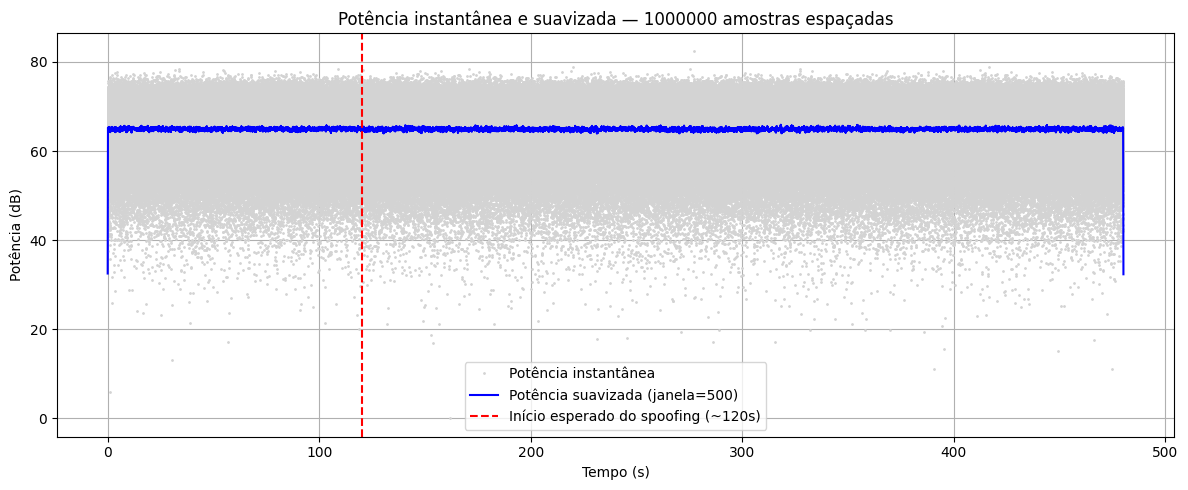

In [10]:
filename = '../cleanStatic.bin'

signal_analyze(filename)

### Spoofed Signal

Arquivo: ../ds2.bin, bytes=45,717,913,600, amostras=11,429,478,400
[55.215893 50.805435 53.125095 ... 63.34102  48.140343 67.04022 ]


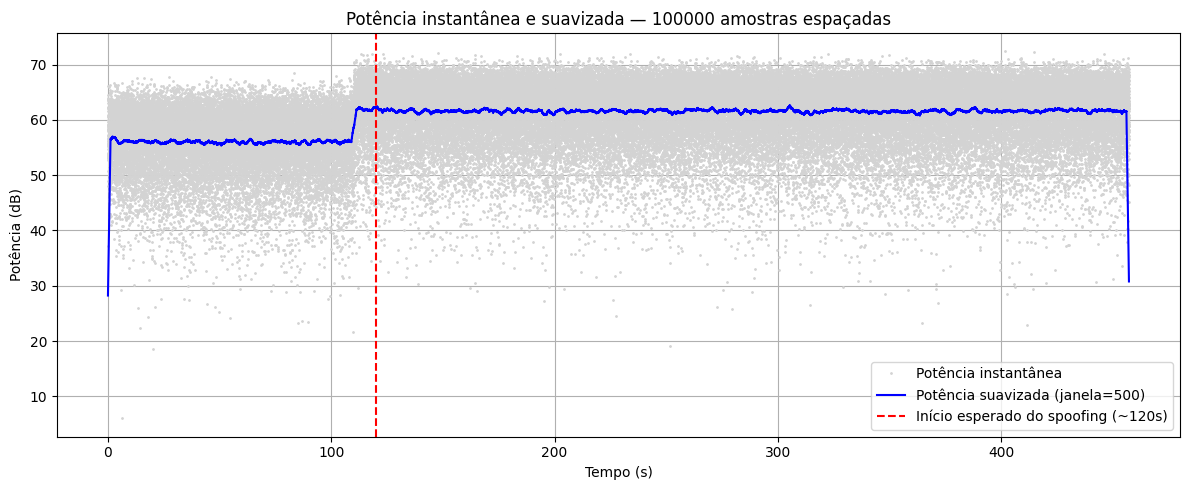

In [86]:
filename = '../ds2.bin'

signal_analyze(filename)